# FIFA World Cup 2026 – Linear Regression 2.2

**Linear Regression 2.2** – predict the **goals scored by a team** in a match (208 rows, 8 explanatory variables).

All explanatory variables are known before kick-off. At most 4 variables are shared between the two models.

**Workflow**
1. Setup
2. Load and validate the dataset
3. Variable definitions and requirement checks
4. Exploratory data analysis (EDA)
5. Modelling functions
6. Model 2.2: fit, evaluate, check assumptions
7. Other models compared with linear regression
8. Summary of results

## 1. Import Libraries

In [1]:
%matplotlib inline
import warnings
from IPython.display import display
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, GroupShuffleSplit,
                                     RepeatedKFold, GroupKFold, cross_validate)
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)
DATA_FILE = DATA_DIR / "dataset_2_2_team_goals.csv"
if not DATA_FILE.exists():          # also accept the file next to the notebook
    DATA_FILE = Path("dataset_2_2_team_goals.csv")

## 2. Load and validate the dataset

The dataset has one row per team per match (208 rows, two rows for each of the 104 matches).
The target goals is the team's goals after 90 minutes plus extra time. Penalty shoot-out goals are not counted.

In [2]:
d22 = pd.read_csv(DATA_FILE)
d22.columns = d22.columns.str.strip().str.lower()

ID_COLS = ["match_id", "team", "opponent", "stage"]
FEATURES_22 = ["fifa_rank", "elo", "host", "rest_days",
               "attack_gf_pg", "opp_defence_ga_pg", "opp_elo", "knockout"]
REQUIRED = ID_COLS + FEATURES_22 + ["goals"]

missing_cols = [col for col in REQUIRED if col not in d22.columns]
assert not missing_cols, f"Missing columns in dataset: {missing_cols}"

d22["stage"] = d22["stage"].str.strip()
for col in FEATURES_22 + ["goals"]:
    d22[col] = pd.to_numeric(d22[col], errors="coerce")

print("Shape:", d22.shape)
print("Stages:", d22["stage"].value_counts().to_dict())
display(d22.head())

Shape: (208, 13)
Stages: {'Group': 144, 'Round of 32': 32, 'Round of 16': 16, 'Quarter-final': 8, 'Semi-final': 4, 'Third place': 2, 'Final': 2}


,match_id,team,opponent,stage,fifa_rank,elo,host,rest_days,attack_gf_pg,opp_defence_ga_pg,opp_elo,knockout,goals
0,1,Mexico,South Africa,Group,14,1980.7,1,7,1.6,1.0,1663.5,0,2
1,1,South Africa,Mexico,Group,60,1663.5,0,5,1.5,0.4,1980.7,0,0
2,2,Czech Republic,South Korea,Group,39,1802.9,0,7,2.2,1.2,1880.2,0,1
3,2,South Korea,Czech Republic,Group,25,1880.2,0,8,1.5,0.9,1802.9,0,2
4,3,Bosnia and Herzegovina,Canada,Group,64,1652.5,0,6,2.0,0.4,1899.5,0,1


In [3]:
# Data quality checks
na = d22[REQUIRED].isna().sum()
print("Missing values per column (non-zero only):")
print(na[na > 0] if na.any() else "None")

checks = {
    "208 team-matches": len(d22) == 208,
    "Each match_id appears exactly twice": (d22["match_id"].value_counts() == 2).all(),
    "Goals are non-negative integers": ((d22["goals"] >= 0) & (d22["goals"] % 1 == 0)).all(),
    "Host flag is 0/1": d22["host"].isin([0, 1]).all(),
    "Knockout flag is 0/1": d22["knockout"].isin([0, 1]).all(),
    "FIFA rank >= 1": (d22["fifa_rank"] >= 1).all(),
    "Rest days >= 0": (d22["rest_days"] >= 0).all(),
    "A team never plays itself": (d22["team"] != d22["opponent"]).all(),
    "opp_elo matches the opponent's own elo": np.allclose(
        d22.sort_values(["match_id", "team"])["opp_elo"].values,
        d22.sort_values(["match_id", "opponent"])["elo"].values),
}
for k, v in checks.items():
    print(f"{'PASS' if v else 'FAIL'}  {k}")

Missing values per column (non-zero only):
None
PASS  208 team-matches
PASS  Each match_id appears exactly twice
PASS  Goals are non-negative integers
PASS  Host flag is 0/1
PASS  Knockout flag is 0/1
PASS  FIFA rank >= 1
PASS  Rest days >= 0
PASS  A team never plays itself
PASS  opp_elo matches the opponent's own elo


In [4]:
# Handle any remaining missing numeric values: fill with the median and record it.
num_cols = FEATURES_22 + ["goals"]
filled = {col: int(d22[col].isna().sum()) for col in num_cols if d22[col].isna().any()}
d22[num_cols] = d22[num_cols].fillna(d22[num_cols].median())
print("Median-imputed cells:", filled if filled else "none")

# Outlier screen (|z| > 3) on the explanatory variables, for reporting only (not removed).
z = np.abs(stats.zscore(d22[FEATURES_22], nan_policy="omit"))
outliers = (pd.DataFrame(z, columns=FEATURES_22) > 3).sum()
print("\nValues with |z| > 3 by column:")
print(outliers[outliers > 0] if outliers.any() else "none")

Median-imputed cells: none

Values with |z| > 3 by column:
host         15
rest_days     1
dtype: int64


## 3. Variable definitions and requirement checks

### Dataset 2.2: one row per team per match (208 rows). Target: `goals`

| # | Variable | Definition |
|---|---|---|
| 1 | `fifa_rank` ★ | Team's FIFA rank |
| 2 | `elo` ★ | Team's pre-match Elo rating |
| 3 | `host` ★ | 1 if the team is a host nation (USA, Canada, Mexico) |
| 4 | `rest_days` ★ | Days since the team's previous match |
| 5 | `attack_gf_pg` | Team's goals scored per game, last 10 internationals |
| 6 | `opp_defence_ga_pg` | Opponent's goals conceded per game, last 10 internationals |
| 7 | `opp_elo` | Opponent's pre-match Elo rating |
| 8 | `knockout` | 1 if the match is in the knockout stage |

★ = shared concept (exactly **4** shared, which is within the limit of 4).

In [5]:
# ---------- Requirement checks ----------
# Features of the other model (Linear Regression 2.1), used only to confirm at most 4 shared variables.
FEATURES_21 = ["rank_diff", "elo_diff", "host_diff", "rest_diff", "wc_apps_diff", "form_ppg_diff", "h2h_gd_pg", "elo_momentum_diff"]
CONCEPT = {  # underlying piece of information behind each variable
    "rank_diff": "fifa_rank", "elo_diff": "elo", "host_diff": "host", "rest_diff": "rest",
    "wc_apps_diff": "wc_apps", "form_ppg_diff": "ppg", "h2h_gd_pg": "h2h",
    "elo_momentum_diff": "elo_change", "fifa_rank": "fifa_rank", "elo": "elo",
    "host": "host", "rest_days": "rest", "attack_gf_pg": "gf_pg",
    "opp_defence_ga_pg": "opp_ga_pg", "opp_elo": "opp_elo", "knockout": "stage",
}
shared = set(CONCEPT[f] for f in FEATURES_21) & set(CONCEPT[f] for f in FEATURES_22)
assert len(d22) == 208 and len(FEATURES_22) == 8, "Dataset 2.2 must be 208 rows x 8 features"
assert len(shared) <= 4, f"Too many shared variables: {shared}"
print(f"Dataset 2.2: {d22.shape}")
print(f"Shared variables ({len(shared)}): {sorted(shared)}")

Dataset 2.2: (208, 13)
Shared variables (4): ['elo', 'fifa_rank', 'host', 'rest']


## 4. Exploratory data analysis

In [6]:
display(d22[FEATURES_22 + ["goals"]].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
fifa_rank,208.0,27.73,22.93,1.0,8.75,22.5,40.00,85.0
elo,208.0,1926.58,168.91,1566.8,1809.72,1918.0,2035.43,2299.5
host,208.0,0.07,0.26,0.0,0.00,0.0,0.00,1.0
rest_days,208.0,6.28,5.18,3.0,5.00,6.0,6.25,76.0
attack_gf_pg,208.0,1.96,0.67,0.7,1.30,1.9,2.50,3.7
opp_defence_ga_pg,208.0,0.87,0.42,0.2,0.50,0.9,1.00,2.0
opp_elo,208.0,1926.58,168.91,1566.8,1809.72,1918.0,2035.43,2299.5
knockout,208.0,0.31,0.46,0.0,0.00,0.0,1.00,1.0
goals,208.0,1.48,1.39,0.0,0.00,1.0,2.00,7.0


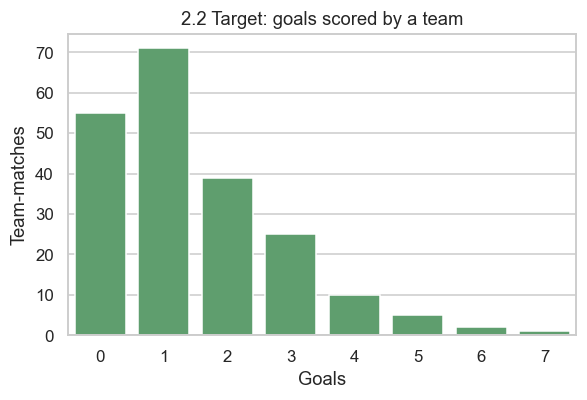

Team goals: mean=1.48, var=1.94, skew=1.15  (var≈mean suggests Poisson-like counts)


In [7]:
fig, ax = plt.subplots(figsize=(5.5, 3.8))
sns.countplot(x=d22["goals"], ax=ax, color="#55A868")
ax.set(title="2.2 Target: goals scored by a team", xlabel="Goals", ylabel="Team-matches")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig1_target_distribution_2_2.png", bbox_inches="tight"); plt.show()

print(f"Team goals: mean={d22.goals.mean():.2f}, var={d22.goals.var():.2f}, "
      f"skew={d22.goals.skew():.2f}  (var≈mean suggests Poisson-like counts)")

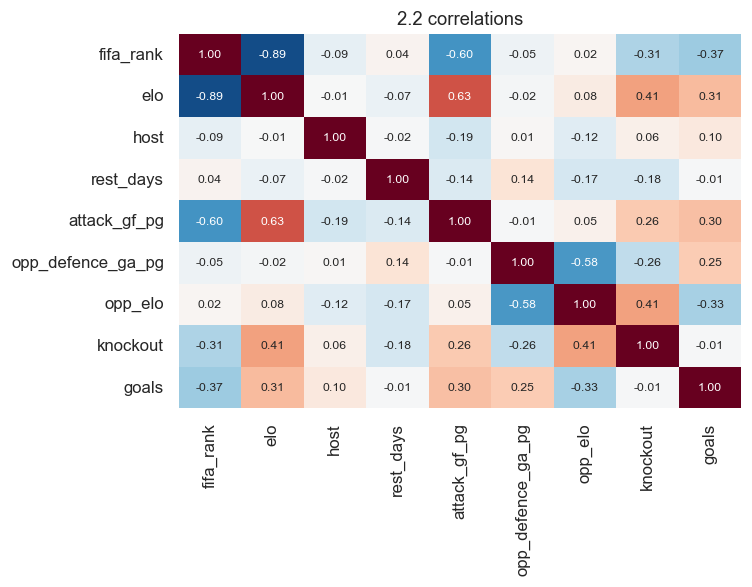

In [8]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(d22[FEATURES_22 + ["goals"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, ax=ax, cbar=False, annot_kws={"size": 8})
ax.set_title("2.2 correlations")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig2_correlation_heatmap_2_2.png", bbox_inches="tight"); plt.show()

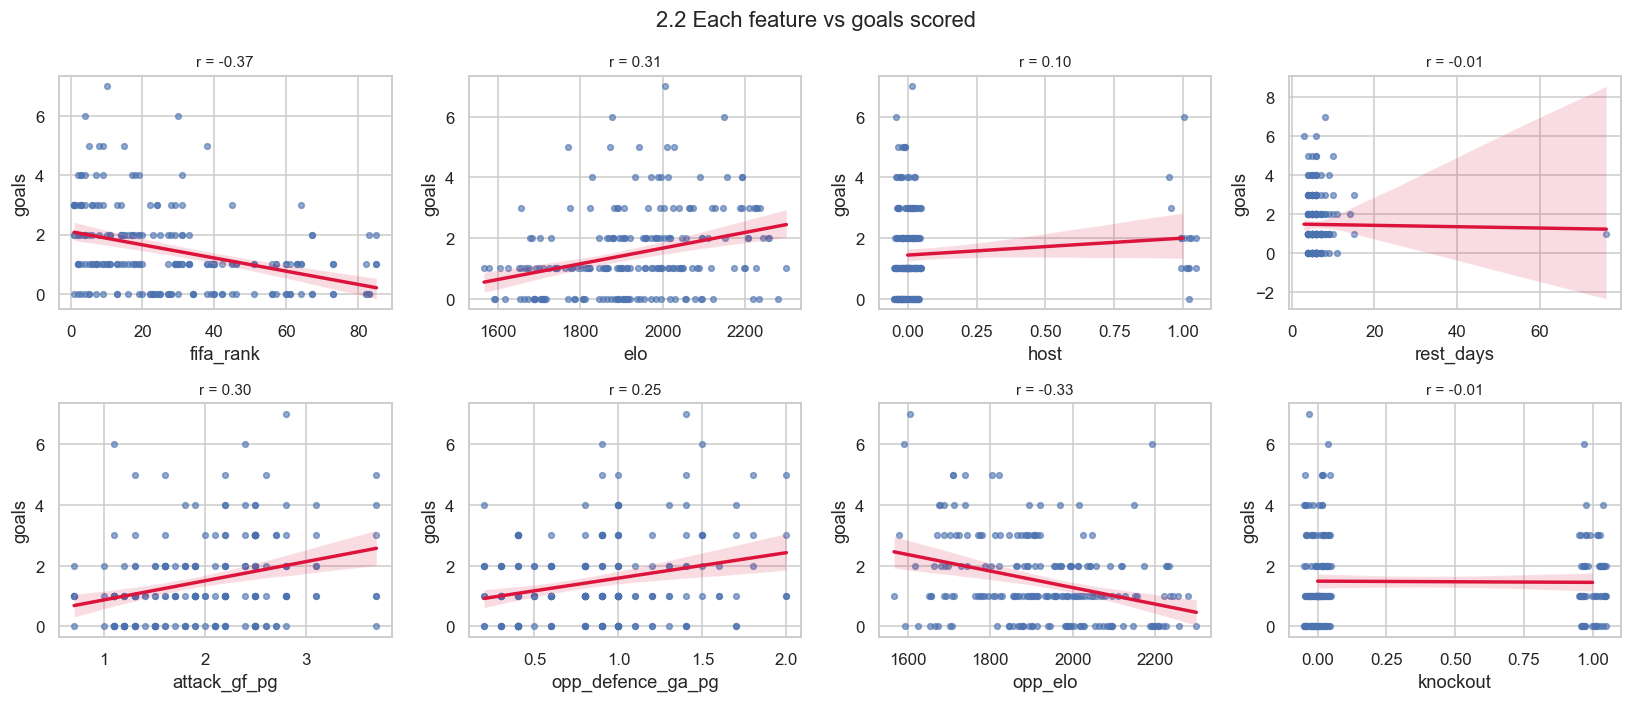

In [9]:
def scatter_grid(df, feats, target, fname, title):
    fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
    for a, f in zip(axes.ravel(), feats):
        sns.regplot(x=df[f], y=df[target], ax=a, scatter_kws={"s": 14, "alpha": .6},
                    line_kws={"color": "crimson"}, x_jitter=0.05 if df[f].nunique() < 5 else 0)
        a.set_title(f"r = {df[f].corr(df[target]):.2f}", fontsize=10)
    for a in axes.ravel()[len(feats):]:          # hide unused panels, if any
        a.set_visible(False)
    fig.suptitle(title); fig.tight_layout()
    fig.savefig(OUT_DIR / fname, bbox_inches="tight")
    display(fig)                                  # force the figure to render in the notebook
    plt.close(fig)

scatter_grid(d22, FEATURES_22, "goals", "fig3_scatter_2_2.png", "2.2 Each feature vs goals scored")

## 5. Modelling functions

Evaluation approach:

* **Multicollinearity:** VIF (variance inflation factor) for each feature. VIF > 5 is a concern and VIF > 10 is severe.
* **Inference:** an OLS fit on the full data (statsmodels) gives coefficients, p-values, R² and adjusted R².
* **Hold-out test:** an 80/20 split by match, with metrics R², RMSE and MAE, compared against a *mean-only baseline*.
* **Cross-validation:** a **GroupKFold by match** keeps both rows of one match in the same fold, so nothing leaks between folds.
* **Assumption checks:** residuals vs fitted (linearity and equal variance), a Q-Q plot and Shapiro–Wilk test (normality), Breusch–Pagan (heteroscedasticity), and Durbin–Watson (independence).

In [10]:
def vif_table(X):
    Xc = sm.add_constant(X)
    return (pd.DataFrame({"feature": X.columns,
                          "VIF": [variance_inflation_factor(Xc.values, i + 1) for i in range(X.shape[1])]})
              .sort_values("VIF", ascending=False).round(2))

def metrics(y, p):
    return {"R2": r2_score(y, p), "RMSE": mean_squared_error(y, p) ** 0.5, "MAE": mean_absolute_error(y, p)}

def holdout_eval(X, y, groups=None):
    if groups is None:
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
    else:
        tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
                      .split(X, y, groups))
        Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
    lr = LinearRegression().fit(Xtr, ytr)
    base = DummyRegressor(strategy="mean").fit(Xtr, ytr)
    res = pd.DataFrame({
        "Linear regression (train)": metrics(ytr, lr.predict(Xtr)),
        "Linear regression (test)": metrics(yte, lr.predict(Xte)),
        "Mean baseline (test)": metrics(yte, base.predict(Xte)),
    }).T.round(3)
    return res, yte, lr.predict(Xte)

def cv_eval(X, y, groups=None):
    scoring = {"R2": "r2", "RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error"}
    cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE) if groups is None else GroupKFold(n_splits=5)
    rows = {}
    for name, model in [("Linear regression", LinearRegression()), ("Mean baseline", DummyRegressor())]:
        s = cross_validate(model, X, y, cv=cv, scoring=scoring, groups=groups)
        rows[name] = {f"{k} mean": abs(s[f"test_{k}"]).mean() if k != "R2" else s[f"test_{k}"].mean()
                      for k in scoring} | {"R2 sd": s["test_R2"].std()}
    return pd.DataFrame(rows).T.round(3)

def standardised_coefs(X, y):
    m = make_pipeline(StandardScaler(), LinearRegression()).fit(X, y)
    return pd.Series(m[-1].coef_, index=X.columns).sort_values(key=abs, ascending=False)

def diagnostics(ols, title, fname):
    fitted, resid = ols.fittedvalues, ols.resid
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    sns.scatterplot(x=fitted, y=resid, ax=ax[0], s=18, alpha=.7)
    ax[0].axhline(0, color="crimson", ls="--"); ax[0].set(title="Residuals vs fitted", xlabel="Fitted", ylabel="Residual")
    sm.qqplot(resid, line="45", fit=True, ax=ax[1]); ax[1].set_title("Normal Q-Q")
    sns.histplot(resid, kde=True, ax=ax[2]); ax[2].set_title("Residual distribution")
    fig.suptitle(title); plt.tight_layout(); plt.savefig(OUT_DIR / fname, bbox_inches="tight"); plt.show()
    bp = het_breuschpagan(resid, ols.model.exog)
    sw = stats.shapiro(resid)
    return pd.Series({"Breusch-Pagan p": bp[1], "Shapiro-Wilk p": sw.pvalue,
                      "Durbin-Watson": durbin_watson(resid)}).round(4)

def actual_vs_pred(y, p, title, fname):
    fig, ax = plt.subplots(figsize=(5, 4.5))
    ax.scatter(y + np.random.uniform(-.1, .1, len(y)), p, s=22, alpha=.7)
    lim = [min(y.min(), p.min()) - .5, max(y.max(), p.max()) + .5]
    ax.plot(lim, lim, "--", color="crimson"); ax.set(xlim=lim, ylim=lim, xlabel="Actual (jittered)",
                                                     ylabel="Predicted", title=title)
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, bbox_inches="tight"); plt.show()

## 6. Linear Regression 2.2: predicting team goals

In [11]:
X2 = d22[FEATURES_22]
y2 = d22["goals"]
groups2 = d22["match_id"]

print("Variance inflation factors:")
display(vif_table(X2))

Variance inflation factors:


,feature,VIF
1,elo,6.09
0,fifa_rank,5.65
4,attack_gf_pg,1.86
6,opp_elo,1.77
5,opp_defence_ga_pg,1.53
7,knockout,1.49
2,host,1.17
3,rest_days,1.07


In [12]:
ols2 = sm.OLS(y2, sm.add_constant(X2)).fit()
print(ols2.summary())

coef2 = pd.DataFrame({"coef": ols2.params, "p_value": ols2.pvalues,
                       "CI 2.5%": ols2.conf_int()[0], "CI 97.5%": ols2.conf_int()[1]}).round(4)
coef2.to_csv(OUT_DIR / "table_coefficients_2_2.csv")

                            OLS Regression Results                            
Dep. Variable:                  goals   R-squared:                       0.267
Model:                            OLS   Adj. R-squared:                  0.238
Method:                 Least Squares   F-statistic:                     9.082
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.29e-10
Time:                        23:05:18   Log-Likelihood:                -331.28
No. Observations:                 208   AIC:                             680.6
Df Residuals:                     199   BIC:                             710.6
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 4.4205      2.85

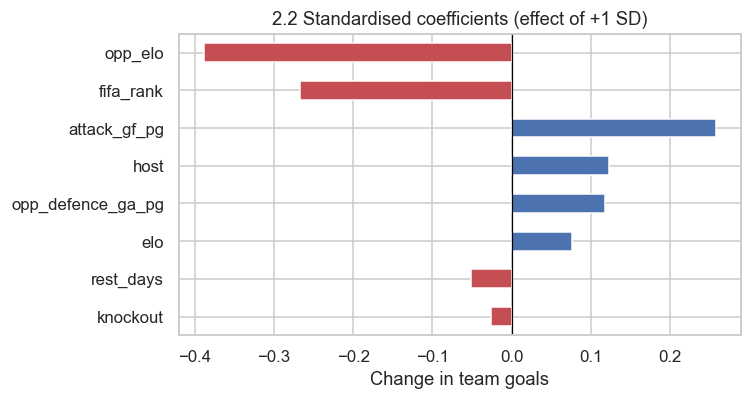

In [13]:
std2 = standardised_coefs(X2, y2)
fig, ax = plt.subplots(figsize=(7, 3.8))
std2[::-1].plot.barh(ax=ax, color=["#C44E52" if v < 0 else "#4C72B0" for v in std2[::-1]])
ax.axvline(0, color="black", lw=.8)
ax.set(title="2.2 Standardised coefficients (effect of +1 SD)", xlabel="Change in team goals")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig4_std_coefs_2_2.png", bbox_inches="tight"); plt.show()

Hold-out evaluation (80/20, split by match):


,R2,RMSE,MAE
Linear regression (train),0.271,1.184,0.884
Linear regression (test),0.233,1.228,1.030
Mean baseline (test),-0.000,1.402,1.187


GroupKFold (5 folds, grouped by match):


,R2 mean,RMSE mean,MAE mean,R2 sd
Linear regression,0.157,1.254,0.971,0.064
Mean baseline,-0.033,1.389,1.116,0.045


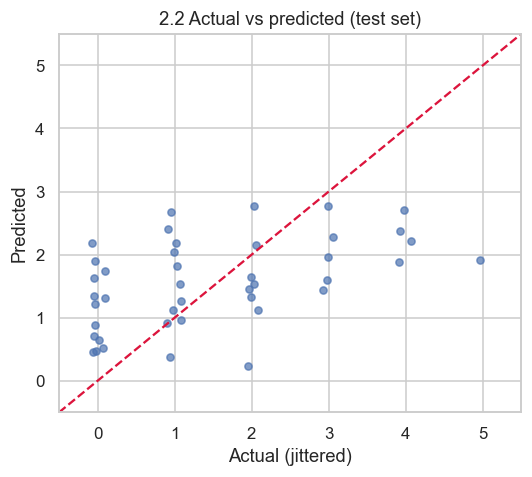

In [14]:
holdout2, yte2, pte2 = holdout_eval(X2, y2, groups2)
print("Hold-out evaluation (80/20, split by match):")
display(holdout2)

cv2 = cv_eval(X2, y2, groups2)
print("GroupKFold (5 folds, grouped by match):")
display(cv2)

actual_vs_pred(yte2, pte2, "2.2 Actual vs predicted (test set)",
               "fig5_actual_vs_pred_2_2.png")

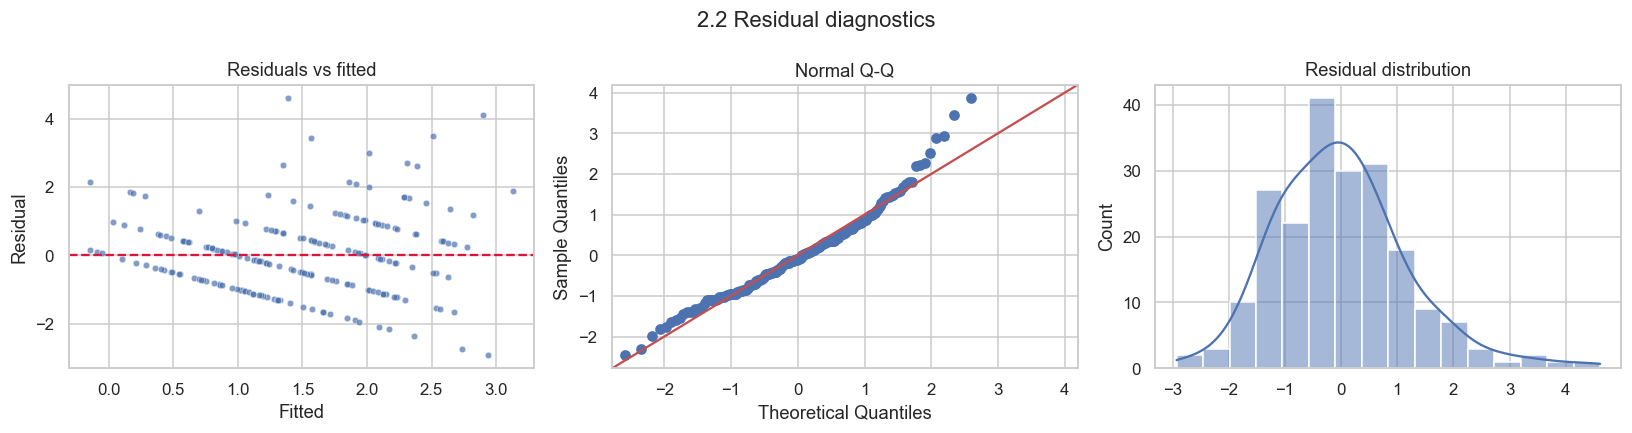

Breusch-Pagan p    0.0323
Shapiro-Wilk p     0.0001
Durbin-Watson      1.8546
dtype: float64

Interpretation guide: BP p < 0.05 means heteroscedasticity; SW p < 0.05 means non-normal residuals; DW close to 2 means independent residuals.


In [15]:
diag2 = diagnostics(ols2, "2.2 Residual diagnostics", "fig6_diagnostics_2_2.png")
print(diag2)
print("\nInterpretation guide: BP p < 0.05 means heteroscedasticity; SW p < 0.05 means non-normal residuals;"
      " DW close to 2 means independent residuals.")

## 7. Other models compared with linear regression

In [16]:
from sklearn.linear_model import RidgeCV, LassoCV, PoissonRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.base import clone

MODELS = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    "Ridge regression": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50))),
    "Lasso regression": make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=RANDOM_STATE, max_iter=10000)),
    "Poisson regression": make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-4, max_iter=1000)),
    "Random forest": RandomForestRegressor(n_estimators=500, min_samples_leaf=5,
                                           random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=2,
                                                   subsample=0.8, random_state=RANDOM_STATE),
}

# Same hold-out split as Section 6 (80/20, grouped by match)
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
              .split(X2, y2, groups2))
Xtr, Xte, ytr, yte = X2.iloc[tr], X2.iloc[te], y2.iloc[tr], y2.iloc[te]

# Same cross-validation as Section 6 (GroupKFold by match)
scoring = {"R2": "r2", "RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error"}
gkf = GroupKFold(n_splits=5)

rows, test_preds, fitted_models = {}, {}, {}
for name, model in MODELS.items():
    m = clone(model).fit(Xtr, ytr)
    p_tr, p_te = m.predict(Xtr), m.predict(Xte)
    s = cross_validate(model, X2, y2, cv=gkf, scoring=scoring, groups=groups2)
    rows[name] = {
        "Train R2": r2_score(ytr, p_tr),
        "Test R2": r2_score(yte, p_te),
        "Test RMSE": mean_squared_error(yte, p_te) ** 0.5,
        "Test MAE": mean_absolute_error(yte, p_te),
        "CV R2 mean": s["test_R2"].mean(),
        "CV R2 sd": s["test_R2"].std(),
        "CV RMSE mean": -s["test_RMSE"].mean(),
        "CV MAE mean": -s["test_MAE"].mean(),
    }
    test_preds[name] = p_te
    fitted_models[name] = m

comparison2 = pd.DataFrame(rows).T.round(3)
comparison2 = comparison2.sort_values("CV RMSE mean")
comparison2.to_csv(OUT_DIR / "table_model_comparison_2_2.csv")
print("Model comparison (sorted by CV RMSE, lower is better):")
display(comparison2)

Model comparison (sorted by CV RMSE, lower is better):


,Train R2,Test R2,Test RMSE,Test MAE,CV R2 mean,CV R2 sd,CV RMSE mean,CV MAE mean
Ridge regression,0.258,0.222,1.236,1.038,0.182,0.050,1.235,0.951
Lasso regression,0.256,0.242,1.221,1.026,0.180,0.034,1.240,0.960
Linear regression,0.271,0.233,1.228,1.030,0.157,0.064,1.254,0.971
Poisson regression,0.299,0.252,1.212,1.010,0.079,0.225,1.290,0.958
Random forest,0.534,0.246,1.217,0.984,0.104,0.061,1.295,0.988
Gradient boosting,0.730,-0.174,1.518,1.155,0.071,0.070,1.320,0.999
Mean baseline,0.000,-0.000,1.402,1.187,-0.033,0.045,1.389,1.116


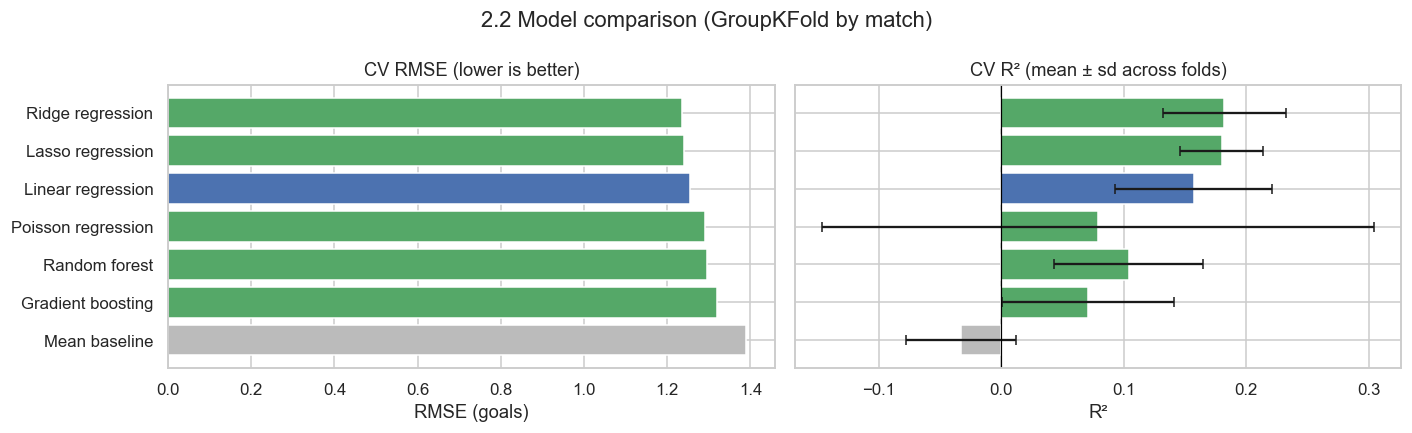

In [17]:
# Visual comparison: cross-validated RMSE and R² for every model
order = comparison2.index[::-1]
colors = ["#4C72B0" if n == "Linear regression" else ("#BBBBBB" if n == "Mean baseline" else "#55A868")
          for n in order]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].barh(order, comparison2.loc[order, "CV RMSE mean"], color=colors)
ax[0].set(title="CV RMSE (lower is better)", xlabel="RMSE (goals)")
ax[1].barh(order, comparison2.loc[order, "CV R2 mean"], color=colors,
           xerr=comparison2.loc[order, "CV R2 sd"], capsize=3)
ax[1].axvline(0, color="black", lw=.8)
ax[1].set(title="CV R² (mean ± sd across folds)", xlabel="R²")
ax[1].set_yticklabels([])
fig.suptitle("2.2 Model comparison (GroupKFold by match)")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig7_model_comparison_2_2.png", bbox_inches="tight"); plt.show()

### 7.1 Poisson regression: interpreting the coefficients

A Poisson regression with a log link is fitted on the full data with statsmodels. Each coefficient is shown as a **rate ratio** `exp(coef)`: the factor by which expected goals change when the feature increases by 1 unit (for example, a rate ratio of 1.20 means 20% more goals).

In [18]:
pois2 = sm.GLM(y2, sm.add_constant(X2), family=sm.families.Poisson()).fit()
print(pois2.summary())

pois_tbl2 = pd.DataFrame({
    "coef": pois2.params,
    "rate ratio exp(coef)": np.exp(pois2.params),
    "p_value": pois2.pvalues,
    "RR CI 2.5%": np.exp(pois2.conf_int()[0]),
    "RR CI 97.5%": np.exp(pois2.conf_int()[1]),
}).round(4)
pois_tbl2.to_csv(OUT_DIR / "table_poisson_coefficients_2_2.csv")
display(pois_tbl2)

# Over-dispersion check: Poisson assumes variance = mean (ratio close to 1)
print(f"Pearson chi² / df = {pois2.pearson_chi2 / pois2.df_resid:.3f}  (values well above 1 suggest over-dispersion)")

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  goals   No. Observations:                  208
Model:                            GLM   Df Residuals:                      199
Model Family:                 Poisson   Df Model:                            8
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -298.35
Date:                Tue, 13 Oct 2026   Deviance:                       216.79
Time:                        23:05:43   Pearson chi2:                     191.
No. Iterations:                     5   Pseudo R-squ. (CS):             0.3059
Covariance Type:            nonrobust                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 3.0472      2.01

,coef,rate ratio exp(coef),p_value,RR CI 2.5%,RR CI 97.5%
const,3.0472,21.0557,0.1298,0.4085,1085.2384
fifa_rank,-0.0134,0.9867,0.0543,0.9733,1.0002
elo,-0.0000,1.0000,0.9990,0.9984,1.0016
host,0.3077,1.3603,0.1540,0.8911,2.0767
rest_days,-0.0057,0.9943,0.6442,0.9707,1.0186
attack_gf_pg,0.2324,1.2617,0.0391,1.0117,1.5735
opp_defence_ga_pg,0.1683,1.1833,0.2969,0.8625,1.6235
opp_elo,-0.0016,0.9984,0.0006,0.9976,0.9993
knockout,-0.0087,0.9914,0.9537,0.7400,1.3281


Pearson chi² / df = 0.962  (values well above 1 suggest over-dispersion)


### 7.2 Which features matter? (permutation importance)

Permutation importance measures how much the test RMSE gets worse when one feature's values are randomly shuffled. It works the same way for every model, so the linear and tree-based models can be compared directly.

,Linear regression,Poisson regression,Random forest,Gradient boosting
attack_gf_pg,0.0860,0.1095,0.0113,0.0443
opp_elo,0.0711,0.0625,0.0745,-0.0692
fifa_rank,0.0497,0.1067,0.1784,0.1750
elo,0.0251,0.0074,0.0253,-0.0192
host,0.0102,0.0225,-0.0001,0.0165
rest_days,0.0031,0.0040,-0.0003,-0.0119
opp_defence_ga_pg,-0.0030,-0.0007,-0.0344,-0.0512
knockout,-0.0053,-0.0035,-0.0017,-0.0288


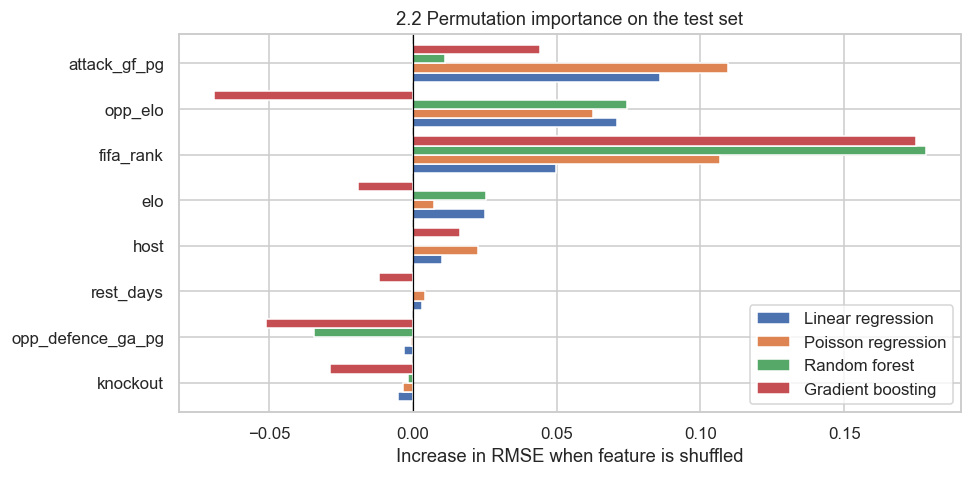

In [19]:
imp_models = ["Linear regression", "Poisson regression", "Random forest", "Gradient boosting"]
imp = {}
for name in imp_models:
    r = permutation_importance(fitted_models[name], Xte, yte, n_repeats=30,
                               random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error")
    imp[name] = pd.Series(r.importances_mean, index=X2.columns)
imp2 = pd.DataFrame(imp).sort_values("Linear regression", ascending=False).round(4)
imp2.to_csv(OUT_DIR / "table_permutation_importance_2_2.csv")
display(imp2)

fig, ax = plt.subplots(figsize=(9, 4.5))
imp2[::-1].plot.barh(ax=ax, width=.8)
ax.axvline(0, color="black", lw=.8)
ax.set(title="2.2 Permutation importance on the test set", xlabel="Increase in RMSE when feature is shuffled")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig8_permutation_importance_2_2.png", bbox_inches="tight"); plt.show()

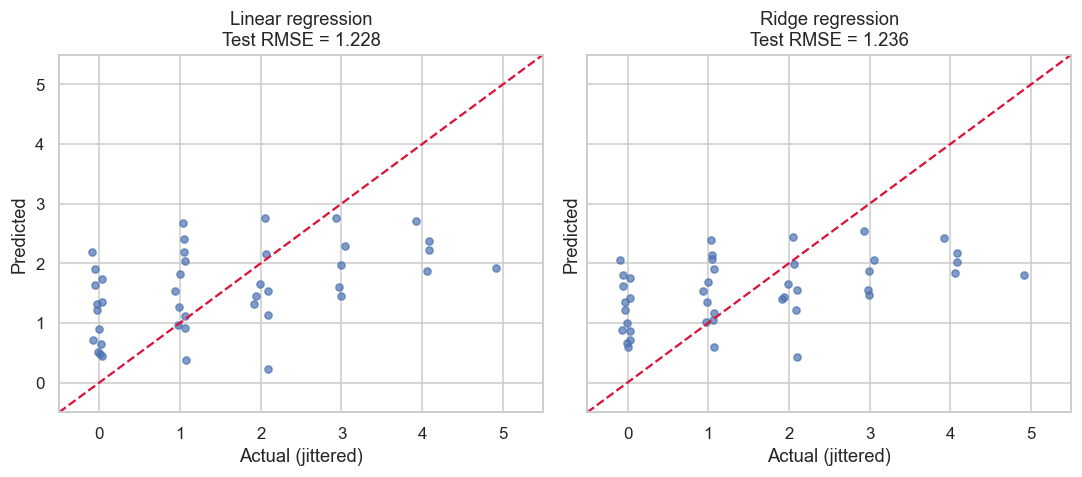

Best model other than linear regression (by CV RMSE): Ridge regression


In [20]:
# Actual vs predicted on the test set for the linear model and the best alternative model
best_alt = [n for n in comparison2.index if n not in ("Linear regression", "Mean baseline")][0]
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
jit = np.random.default_rng(RANDOM_STATE).uniform(-.1, .1, len(yte))
for a, name in zip(ax, ["Linear regression", best_alt]):
    p = test_preds[name]
    a.scatter(yte + jit, p, s=22, alpha=.7)
    lim = [-0.5, max(yte.max(), p.max()) + .5]
    a.plot(lim, lim, "--", color="crimson")
    a.set(xlim=lim, ylim=lim, xlabel="Actual (jittered)", ylabel="Predicted",
          title=f"{name}\nTest RMSE = {comparison2.loc[name, 'Test RMSE']:.3f}")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig9_actual_vs_pred_best_2_2.png", bbox_inches="tight"); plt.show()
print("Best model other than linear regression (by CV RMSE):", best_alt)

## 8. Summary of results

In [21]:
summary = pd.DataFrame({
    "Model": ["2.2 Team goals"],
    "Rows": [len(d22)],
    "R² (full fit)": [ols2.rsquared],
    "Adj. R² (full fit)": [ols2.rsquared_adj],
    "F-test p": [ols2.f_pvalue],
    "Test R²": [holdout2.loc["Linear regression (test)", "R2"]],
    "Test RMSE": [holdout2.loc["Linear regression (test)", "RMSE"]],
    "Baseline test RMSE": [holdout2.loc["Mean baseline (test)", "RMSE"]],
    "CV R² (mean)": [cv2.loc["Linear regression", "R2 mean"]],
    "CV RMSE (mean)": [cv2.loc["Linear regression", "RMSE mean"]],
    "Significant features (p<0.05)": [
        ", ".join(coef2.index[(coef2.p_value < .05) & (coef2.index != "const")]) or "none"],
}).round(3)
summary.to_csv(OUT_DIR / "table_model_summary_2_2.csv", index=False)
display(summary.T)

print("\nAll models (sorted by CV RMSE):")
display(comparison2[["Test R2", "Test RMSE", "CV R2 mean", "CV RMSE mean"]])

,0
Model,2.2 Team goals
Rows,208
R² (full fit),0.267
Adj. R² (full fit),0.238
F-test p,0.0
Test R²,0.233
Test RMSE,1.228
Baseline test RMSE,1.402
CV R² (mean),0.157
CV RMSE (mean),1.254



All models (sorted by CV RMSE):


,Test R2,Test RMSE,CV R2 mean,CV RMSE mean
Ridge regression,0.222,1.236,0.182,1.235
Lasso regression,0.242,1.221,0.180,1.240
Linear regression,0.233,1.228,0.157,1.254
Poisson regression,0.252,1.212,0.079,1.290
Random forest,0.246,1.217,0.104,1.295
Gradient boosting,-0.174,1.518,0.071,1.320
Mean baseline,-0.000,1.402,-0.033,1.389
